# 🧭 Projeto 2º Bimestre — Notebook 2: Aprendizado Não Supervisionado (Clustering K-Means)
**Disciplina:** Ciência de Dados &nbsp;|&nbsp; **Etapa:** Checkpoint 1 (Aula 11)

**Pergunta de negócio:** *Quais perfis naturais de zonas residenciais existem na base, considerando valor do imóvel, IPTU, renda média da zona e número de cômodos, sem usar o rótulo `Tipo_Zona`?*

**Pipeline (Aula 11):** seleção das colunas contínuas → `StandardScaler` (Z-Score) → escolha de $K$ por **Cotovelo + Silhueta** → `KMeans` final → tabela `.groupby('Cluster')` → **Personas de negócio** → comparação com `Tipo_Zona`.

> **Pré-requisito:** rode antes o Notebook 1 (gera `housing_tax_data_limpo.csv`).

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score


# Download latest version



pd.set_option('display.max_columns', 20)
pd.set_option('display.width', 1000)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 5)

SEED = 42
ARQ_LIMPO = 'housing_tax_data_limpo.csv'
COLUNAS_CLUSTER = ['Valor_Imovel_Mil_BRL', 'Imposto_IPTU_Anual_BRL',
                   'Renda_Media_Zona_Mil_BRL', 'Media_Comodos_Por_Casa']

if not os.path.exists(ARQ_LIMPO):
    raise FileNotFoundError(f"'{ARQ_LIMPO}' não encontrado. Rode primeiro o Notebook 1 (Data Wrangling).")

df = pd.read_csv(ARQ_LIMPO)
print(f"✅ Base limpa carregada: {df.shape[0]} linhas x {df.shape[1]} colunas")
print("Nulos nas variáveis de clustering:", int(df[COLUNAS_CLUSTER].isnull().sum().sum()))
display(df[COLUNAS_CLUSTER].describe().round(2))

✅ Base limpa carregada: 19465 linhas x 12 colunas
Nulos nas variáveis de clustering: 0


,Valor_Imovel_Mil_BRL,Imposto_IPTU_Anual_BRL,Renda_Media_Zona_Mil_BRL,Media_Comodos_Por_Casa
count,19465.00,19465.00,19465.00,19465.00
mean,961.71,9624.08,183.74,5.22
std,486.01,5482.95,78.23,1.19
min,75.00,635.64,25.00,0.85
25%,583.00,5519.97,126.25,4.41
50%,870.00,8462.54,172.41,5.17
75%,1242.00,12517.98,229.17,5.95
max,2495.50,34246.33,657.38,10.58


---
## 1. Por que padronizar? (a "Armadilha da Escala")
As quatro variáveis estão em escalas muito diferentes (cômodos ≈ 5; IPTU ≈ milhares de R$). Sem padronização, a **Distância Euclidiana** é dominada pelas colunas de maior grandeza (aqui, o IPTU) e o K-Means praticamente ignora `Media_Comodos_Por_Casa`.

In [3]:
X = df[COLUNAS_CLUSTER].copy()

# Quanto cada variável "pesa" na distância euclidiana SEM padronizar (proporção da variância)
var = X.var()
peso_bruto = (var / var.sum() * 100).round(4)
print("Participação aproximada de cada variável na distância (dados brutos):")
display(peso_bruto.to_frame('% da variância total'))

# Padronização Z-Score (média 0, desvio-padrão 1)
scaler = StandardScaler()
X_padronizado = scaler.fit_transform(X)

df_z = pd.DataFrame(X_padronizado, columns=[c + '_z' for c in COLUNAS_CLUSTER])
print("\nApós o StandardScaler (média ≈ 0 e desvio-padrão ≈ 1 em todas as colunas):")
display(df_z.agg(['mean', 'std']).round(3))

Participação aproximada de cada variável na distância (dados brutos):


,% da variância total
Valor_Imovel_Mil_BRL,0.7794
Imposto_IPTU_Anual_BRL,99.2004
Renda_Media_Zona_Mil_BRL,0.0202
Media_Comodos_Por_Casa,0.0000



Após o StandardScaler (média ≈ 0 e desvio-padrão ≈ 1 em todas as colunas):


,Valor_Imovel_Mil_BRL_z,Imposto_IPTU_Anual_BRL_z,Renda_Media_Zona_Mil_BRL_z,Media_Comodos_Por_Casa_z
mean,0.0,-0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


---
## 2. Escolhendo o número de clusters $K$ (Cotovelo + Silhueta)
A silhueta exige calcular distâncias entre pares de pontos (custo quadrático). Em bases grandes usamos uma **amostra aleatória** (`sample_size`) para estimá-la, o que é uma prática padrão e mantém o resultado confiável.

,K,Inércia (WCSS),Silhueta média
0,2,43300.2,0.4093
1,3,34573.6,0.2916
2,4,27939.3,0.3006
3,5,23973.8,0.2792
4,6,21157.6,0.2675
5,7,19212.8,0.2560
6,8,17823.3,0.2550


👉 K com maior silhueta: 2


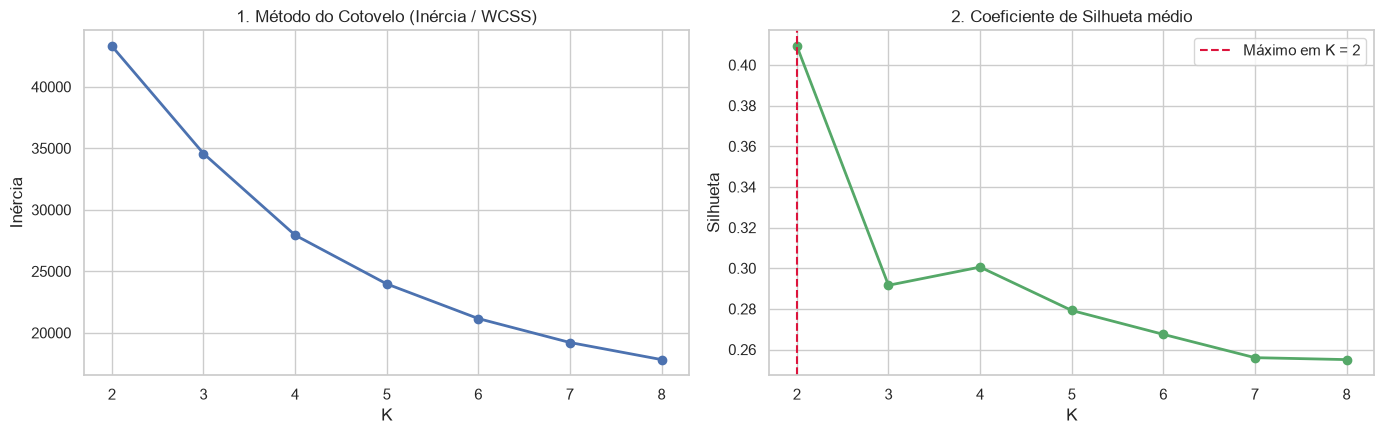

In [4]:
faixa_k = range(2, 9)
inercias, silhuetas = [], []

for k in faixa_k:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    rotulos = km.fit_predict(X_padronizado)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_padronizado, rotulos,
                                      sample_size=min(5000, len(X_padronizado)), random_state=SEED))

df_diag = pd.DataFrame({'K': list(faixa_k),
                        'Inércia (WCSS)': np.round(inercias, 1),
                        'Silhueta média': np.round(silhuetas, 4)})
display(df_diag)

K_SUGERIDO = int(df_diag.loc[df_diag['Silhueta média'].idxmax(), 'K'])
print(f"👉 K com maior silhueta: {K_SUGERIDO}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(list(faixa_k), inercias, 'bo-', lw=2)
axes[0].set_title('1. Método do Cotovelo (Inércia / WCSS)')
axes[0].set_xlabel('K'); axes[0].set_ylabel('Inércia')
axes[1].plot(list(faixa_k), silhuetas, 'go-', lw=2)
axes[1].axvline(K_SUGERIDO, color='crimson', ls='--', label=f'Máximo em K = {K_SUGERIDO}')
axes[1].set_title('2. Coeficiente de Silhueta médio')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Silhueta'); axes[1].legend()
plt.tight_layout(); plt.show()

> **Decisão do grupo:** a silhueta sugere um $K$, mas o cotovelo costuma ser menos nítido em dados reais. Se o grupo preferir outro valor por **interpretabilidade de negócio** (ex.: $K=3$ para casar com Nobre / Urbana / Suburbana), defina `K_ESCOLHIDO` na célula abaixo e **justifique no relatório**.

In [5]:
K_ESCOLHIDO = None   # ex.: 3. Deixe None para usar o K de maior silhueta
K_FINAL = K_ESCOLHIDO if K_ESCOLHIDO is not None else K_SUGERIDO
print(f"K final adotado: {K_FINAL}")

kmeans_final = KMeans(n_clusters=K_FINAL, random_state=SEED, n_init=10)
df['Cluster'] = kmeans_final.fit_predict(X_padronizado)

print("Tamanho de cada cluster:")
display(df['Cluster'].value_counts().sort_index().to_frame('Qtde_Zonas'))

K final adotado: 2
Tamanho de cada cluster:


,Qtde_Zonas
Cluster,
0,13111
1,6354


---
## 3. Visualização dos clusters

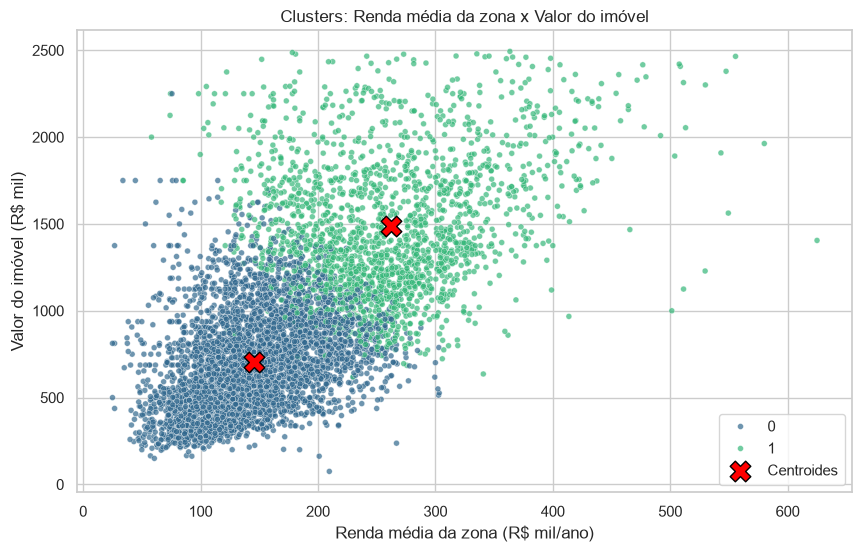

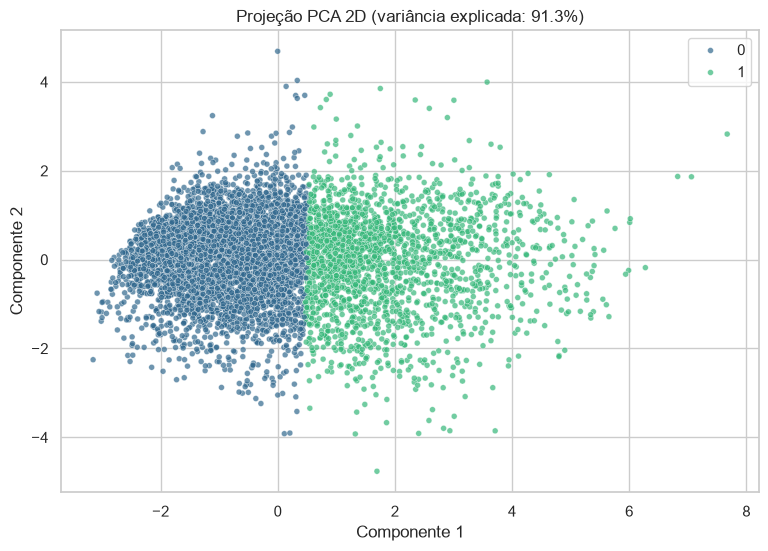

In [6]:
# 3.1 Dois eixos de negócio: Renda x Valor do Imóvel (escala original)
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df.sample(min(6000, len(df)), random_state=SEED),
                x='Renda_Media_Zona_Mil_BRL', y='Valor_Imovel_Mil_BRL',
                hue='Cluster', palette='viridis', s=18, alpha=0.7)
centros = scaler.inverse_transform(kmeans_final.cluster_centers_)
idx_r = COLUNAS_CLUSTER.index('Renda_Media_Zona_Mil_BRL')
idx_v = COLUNAS_CLUSTER.index('Valor_Imovel_Mil_BRL')
plt.scatter(centros[:, idx_r], centros[:, idx_v], c='red', marker='X', s=220, edgecolor='black', label='Centroides')
plt.title('Clusters: Renda média da zona x Valor do imóvel')
plt.xlabel('Renda média da zona (R$ mil/ano)'); plt.ylabel('Valor do imóvel (R$ mil)')
plt.legend(); plt.show()

# 3.2 Projeção PCA 2D (resume as 4 variáveis em 2 componentes)
pca = PCA(n_components=2, random_state=SEED)
comp = pca.fit_transform(X_padronizado)
amostra = np.random.default_rng(SEED).choice(len(df), size=min(6000, len(df)), replace=False)
plt.figure(figsize=(9, 6))
sns.scatterplot(x=comp[amostra, 0], y=comp[amostra, 1], hue=df['Cluster'].values[amostra],
                palette='viridis', s=18, alpha=0.7)
plt.title(f'Projeção PCA 2D (variância explicada: {pca.explained_variance_ratio_.sum()*100:.1f}%)')
plt.xlabel('Componente 1'); plt.ylabel('Componente 2')
plt.show()

---
## 4. Do número frio à estratégia: Personas de Negócio
O `KMeans` devolve apenas rótulos numéricos. Agregamos as médias na **escala original** e ordenamos os clusters pelo valor médio do imóvel para sugerir nomes.

In [7]:
perfil = df.groupby('Cluster').agg(
    Qtde_Zonas=('Cluster', 'count'),
    Valor_Medio_Mil_BRL=('Valor_Imovel_Mil_BRL', 'mean'),
    IPTU_Medio_BRL=('Imposto_IPTU_Anual_BRL', 'mean'),
    Renda_Media_Mil_BRL=('Renda_Media_Zona_Mil_BRL', 'mean'),
    Comodos_Medios=('Media_Comodos_Por_Casa', 'mean'),
).round(2)
perfil['Pct_da_Base'] = (perfil['Qtde_Zonas'] / perfil['Qtde_Zonas'].sum() * 100).round(1)

# Ranking por valor médio -> nomes sugeridos (EDITE conforme a leitura do grupo)
ordem = perfil['Valor_Medio_Mil_BRL'].sort_values().index.tolist()
if K_FINAL == 3:
    nomes = ['Periferia Acessível', 'Classe Média Urbana', 'Zonas Nobres']
elif K_FINAL == 2:
    nomes = ['Zonas de Valor Moderado', 'Zonas Nobres']
else:
    nomes = [f'Perfil {i+1} (do menor para o maior valor)' for i in range(K_FINAL)]
    nomes[0] = 'Periferia / Menor valor'
    nomes[-1] = 'Zonas Nobres / Maior valor'
mapa_persona = {cl: nomes[pos] for pos, cl in enumerate(ordem)}
perfil['Persona_de_Negocio'] = perfil.index.map(mapa_persona)
df['Persona'] = df['Cluster'].map(mapa_persona)

print("📋 TABELA EXECUTIVA DE SEGMENTAÇÃO DE ZONAS:")
display(perfil.sort_values('Valor_Medio_Mil_BRL'))

📋 TABELA EXECUTIVA DE SEGMENTAÇÃO DE ZONAS:


,Qtde_Zonas,Valor_Medio_Mil_BRL,IPTU_Medio_BRL,Renda_Media_Mil_BRL,Comodos_Medios,Pct_da_Base,Persona_de_Negocio
Cluster,,,,,,,
0,13111,707.38,6885.20,145.89,4.84,67.4,Zonas de Valor Moderado
1,6354,1486.49,15275.55,261.85,6.00,32.6,Zonas Nobres


### Ações estratégicas sugeridas (EDITE com a leitura do grupo)
| Persona | Leitura | Ação sugerida |
| :--- | :--- | :--- |
| **Zonas Nobres** | Maior valor, renda e IPTU | Foco em imóveis de alto padrão; revisar base de cálculo do IPTU. |
| **Classe Média Urbana** | Valores e rendas intermediários | Maior volume de negócios; produtos de financiamento. |
| **Periferia Acessível** | Menor valor e renda | Programas de habitação e incentivos; monitorar valorização. |

---
## 5. Validação cruzada: clusters (não supervisionado) vs. `Tipo_Zona` (rótulo definido por renda)
Os clusters foram descobertos **sem** usar `Tipo_Zona`. Se eles coincidirem bastante com as zonas, há evidência de que a estrutura dos dados sustenta a classificação futura.

% de cada Tipo_Zona dentro de cada Persona (linhas somam 100%):


Tipo_Zona,Suburbana,Urbana,Nobre
Persona,,,
Zonas Nobres,3.1,35.1,61.9
Zonas de Valor Moderado,52.9,44.0,3.2


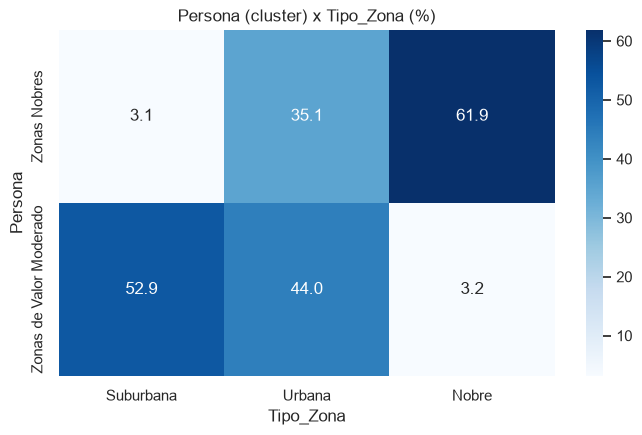

ocean_proximity,<1H Ocean,Inland,Island,Near Bay,Near Ocean
Persona,,,,,
Zonas Nobres,56.3,13.3,0.1,14.8,15.5
Zonas de Valor Moderado,38.2,42.0,0.0,8.8,11.0


In [8]:
tab = pd.crosstab(df['Persona'], df['Tipo_Zona'], normalize='index').mul(100).round(1)
tab = tab[[c for c in ['Suburbana', 'Urbana', 'Nobre'] if c in tab.columns]]
print("% de cada Tipo_Zona dentro de cada Persona (linhas somam 100%):")
display(tab)

plt.figure(figsize=(8, 4.5))
sns.heatmap(tab, annot=True, fmt='.1f', cmap='Blues')
plt.title('Persona (cluster) x Tipo_Zona (%)')
plt.show()

# Perfil geográfico: proximidade do oceano por persona
if 'ocean_proximity' in df.columns:
    display(pd.crosstab(df['Persona'], df['ocean_proximity'], normalize='index').mul(100).round(1))

In [9]:
# Salvando a base com clusters (útil para Checkpoint 2 / Classificação)
df.to_csv('housing_tax_data_clusters.csv', index=False, encoding='utf-8')
print("💾 'housing_tax_data_clusters.csv' salvo.")

💾 'housing_tax_data_clusters.csv' salvo.


---
## 6. Conclusões (preencher com o grupo)
* **K escolhido e justificativa** (cotovelo, silhueta, interpretabilidade): ...
* **Personas descobertas e como diferem em valor, renda, IPTU e cômodos:** ...
* **Relação com `Tipo_Zona`** (a tabela da Seção 5 sustenta a hipótese do projeto?): ...
* **Limitações:** IPTU sintético, valores de 1990 convertidos por cotação fixa, `Tipo_Zona` definido por renda.
* **Implicação para o Checkpoint 2 (Classificação):** ...